# Task02 for the chapter **Linear Regression**

This task is separated into 7 parts.

The last part is about the dataset **Boston**

And we will discuss it in this notebook.

-----
The data contains:

- crim: per capita crime rate by town
- zn: proportion of residential land zoned for lots over 25,000 sq.ft.
- indus: proportion of non-retail business acres per town.
- chas: Nearby Charles River or not
- nox: nitric oxides concentration
- rm: average number of rooms per dwelling
- age: proportion of owner-occupied units built prior to 1940
- dis: weighted distances to five Boston employment centres
- rad: index of accessibility to radial highways
- tax: full-value property-tax rate
- ptratio: pupil-teacher ratio by town
- lstat: % lower status of the population
- medv: Median value of owner-occupied homes

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

boston = pd.read_csv('/content/Boston.csv')
boston = boston.rename ({'Unnamed: 0': 'House'},axis =1)
print(boston.head())
boston.info()

   House     crim    zn  indus  chas    nox     rm   age     dis  rad  tax  \
0      1  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296   
1      2  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242   
2      3  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242   
3      4  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222   
4      5  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222   

   ptratio  lstat  medv  
0     15.3   4.98  24.0  
1     17.8   9.14  21.6  
2     17.8   4.03  34.7  
3     18.7   2.94  33.4  
4     18.7   5.33  36.2  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   House    506 non-null    int64  
 1   crim     506 non-null    float64
 2   zn       506 non-null    float64
 3   indus    506 non-null    float64
 4   chas     506 non-null    int64  
 5  

In [6]:
pip install --upgrade ISLP

In [7]:
'''
  (a) For each predictor, fit a simple linear regression model to predict
  the response. Describe your results. In which of the models is
  there a statistically significant association between the predictor
  and the response? Create some plots to back up your assertions.
'''
import seaborn as sns
import statsmodels.api as sm
from ISLP import load_data

y = boston['crim']
predictors = [col for col in boston.columns if col != 'crim']
summary_results = {}
for p in predictors:
    X = sm.add_constant(boston[p])
    model = sm.OLS(y, X).fit()
    coef = model.params[p]
    p_val = model.pvalues[p]
    summary_results[p] = {'Coefficient': coef, 'P-value': p_val}
results_df = pd.DataFrame(summary_results).T
results_df['Significant? (p < 0.05)'] = results_df['P-value'] < 0.05
print(results_df)

         Coefficient       P-value  Significant? (p < 0.05)
House       0.023967  1.182115e-21                     True
zn         -0.073935  5.506472e-06                     True
indus       0.509776  1.450349e-21                     True
chas       -1.892777  2.094345e-01                    False
nox        31.248531  3.751739e-23                     True
rm         -2.684051  6.346703e-07                     True
age         0.107786  2.854869e-16                     True
dis        -1.550902  8.519949e-19                     True
rad         0.617911  2.693844e-56                     True
tax         0.029742  2.357127e-47                     True
ptratio     1.151983  2.942922e-11                     True
lstat       0.548805  2.654277e-27                     True
medv       -0.363160  1.173987e-19                     True


In [8]:
'''
  (b) Fit a multiple regression model to predict the response using
  all of the predictors. Describe your results.
'''

from ISLP.models import ModelSpec as MS, summarize

predictors = [col for col in boston.columns if col != 'crim']
design = MS(predictors)
X = design.fit_transform(boston)
y = boston['crim']
model_multi = sm.OLS(y, X)
results_multi = model_multi.fit()
summarize(results_multi)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:918: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  return self.fit(X, **fit_params).transform(X)


,coef,std err,t,P>|t|
intercept,13.8701,7.088,1.957,0.051
House,-0.0018,0.003,-0.640,0.523
zn,0.0469,0.019,2.483,0.013
indus,-0.0587,0.084,-0.702,0.483
chas,-0.8051,1.185,-0.680,0.497
nox,-9.8290,5.297,-1.856,0.064
rm,0.6563,0.609,1.078,0.282
age,-0.0027,0.018,-0.149,0.881
dis,-1.0272,0.284,-3.622,0.000
rad,0.6260,0.090,6.946,0.000


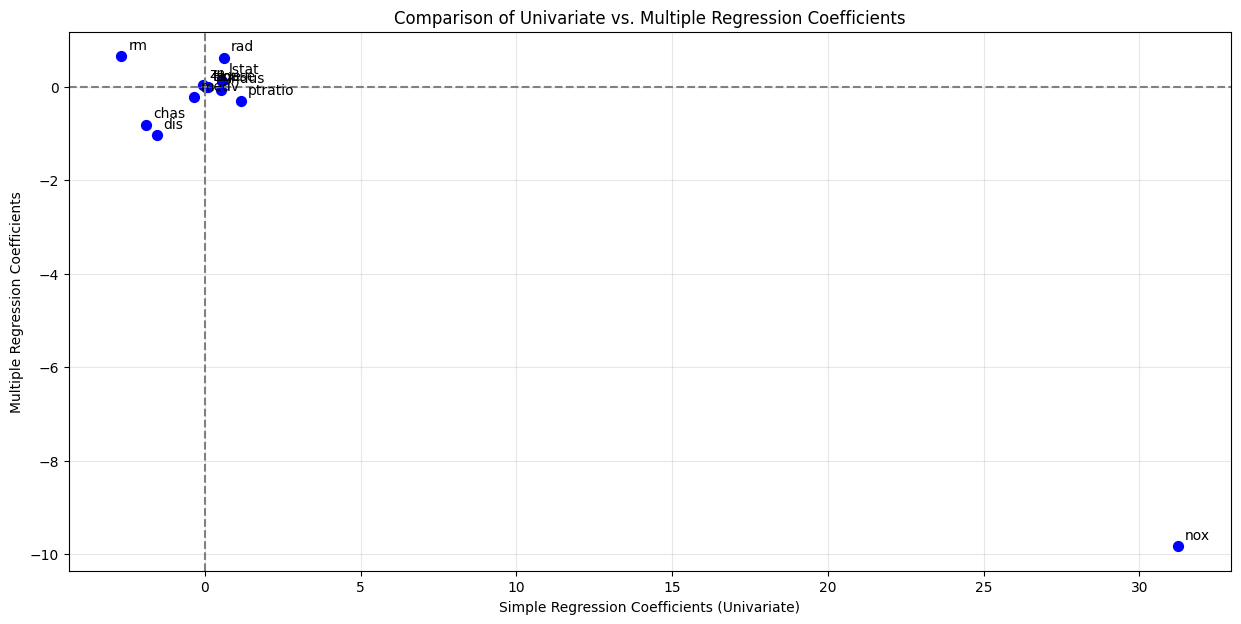

In [11]:
'''
  (c) Create a plot displaying the univariate regression coefficients
  from (a) on the x-axis, and the multiple regression coefficients
  from (b) on the y-axis. That is, each predictor is displayed as a
  single point in the plot. Its coefficient in a simple linear regres-
  sion model is shown on the x-axis, and its coefficient estimate
  in the multiple linear regression model is shown on the y-axis.
'''

univariate_coefs = []
for p in predictors:
    X_simple = sm.add_constant(boston[p])
    model = sm.OLS(y, X_simple).fit()
    univariate_coefs.append(model.params[p])
X_multi = sm.add_constant(boston[predictors])
model_multi = sm.OLS(y, X_multi).fit()
multiple_coefs = [model_multi.params[p] for p in predictors]
plt.figure(figsize = (15, 7))
plt.scatter(univariate_coefs, multiple_coefs, color = 'blue', s = 50)
for i, p in enumerate(predictors):
  plt.annotate(p, (univariate_coefs[i], multiple_coefs[i]),
    textcoords="offset points", xytext=(5,5))
plt.axhline(0, color = 'gray', linestyle = '--')
plt.axvline(0, color = 'gray', linestyle = '--')
plt.xlabel('Simple Regression Coefficients (Univariate)')
plt.ylabel('Multiple Regression Coefficients')
plt.title('Comparison of Univariate vs. Multiple Regression Coefficients')
plt.grid(True, alpha=0.3)
plt.show()